# SecureLogEngine : rapport technique

Projet de Programmation en Python, ING3, ECE Paris.

Équipe : TAGNE CHIBY Ellios, BENBOUJEMAA Manel, SABITY Brahim.

**Objectif.** SecureLogEngine est un outil en ligne de commande qui lit des
fichiers de logs de sécurité, les nettoie, les analyse et signale les
comportements suspects. Les fichiers sont traités ligne par ligne, sans
jamais être chargés entièrement en mémoire.

Ce notebook exécute le vrai code du projet sur les fichiers d'exemple
(`data/samples/`) et illustre chaque partie du cahier des charges.

## 1. Architecture

| Module du cahier des charges | Fichier | Notions Python |
|---|---|---|
| 1. Ingestion | `ingestion/readers.py` | `yield`, `yield from` |
| 1. Parsing | `parsers.py` | `dict`, `tuple`, JSON ou chaîne brute |
| 2. Filtrage | `filters.py` | `filter`, `filter(None, ...)`, `lambda` |
| 2. Normalisation | `normalizer.py` | `map`, f-strings |
| 2. Routage | `router.py` | `match` / `case` |
| 3. Comptages | `aggregation.py` | `defaultdict` |
| 3. Adresses IP | `ip_analysis.py` | `set`, `frozenset`, `\|`, `&`, `-`, `^` |
| 3. Force brute | `bruteforce.py` | `for`, `while`, `break`, `continue`, `else` |
| 4. Moteur de règles | `rules.py` | `*args`, `**kwargs`, fonctions en argument |
| 4. Audit | `audit.py` | `globals()`, `locals()` |

`pipeline.py` enchaîne toutes ces étapes en flux, et `main.py` les
pilote depuis la ligne de commande.

In [1]:
import json
import os
import tempfile

import matplotlib.pyplot as plt

from log_engine.aggregation import count_by_severity, count_by_user
from log_engine.audit import export_audit_report
from log_engine.bruteforce import describe_attacks
from log_engine.ingestion.readers import read_sources
from log_engine.ip_analysis import (
    active_ips,
    compare_with_blacklist,
    error_ips,
    load_blacklist,
)
from log_engine.models import SEVERITY_LEVELS
from log_engine.pipeline import DEFAULT_FILES, process_files
from log_engine.rules import (
    apply_security_rules,
    rule_blacklisted_ips,
    rule_brute_force,
    rule_privilege_escalation,
)
from scripts.memory_demo import (
    create_test_file,
    measure_peak,
    read_all_at_once,
    read_with_generator,
    read_with_list,
    read_with_pipeline,
)

## 2. Lecture en flux (Module 1)

`read_lines` est un générateur : il renvoie les lignes d'un fichier une
par une grâce à `yield`. `read_sources` enchaîne plusieurs fichiers avec
`yield from`. Chaque élément est un tuple `(fichier, numéro, texte)`.

Appeler `read_sources` ne lit rien : chaque `next()` lit une seule ligne.

In [2]:
lines = read_sources(DEFAULT_FILES)
print(lines)
print(next(lines))
print(next(lines))

<generator object read_sources at 0x7f9bd7a195d0>
('auth.log', 1, '2026-11-04T08:00:00Z | INFO | 127.0.0.1:22/TCP | - | SERVICE_START | {"service": "sshd", "pid": 1021}')
('auth.log', 2, '2026-11-04T08:03:12Z | INFO | 10.0.0.15:50122/TCP | alice | AUTH_SUCCESS | {"method": "password"}')


## 3. Pipeline de transformation (Modules 1 et 2)

`process_files` enchaîne, en flux :

1. `read_sources` : lecture des fichiers (`yield from`) ;
2. `remove_empty_lines` : retrait des lignes vides (`filter` + `lambda`) ;
3. `route_line` : choix du parseur selon la forme de la donnée
   (`match` / `case` sur une chaîne, un dictionnaire ou un tuple) ;
4. `remove_invalid` : retrait des lignes illisibles (`filter(None, ...)`) ;
5. `normalize_records` : uniformisation des champs (`map`, f-strings) ;
6. `keep_known_severity` : retrait des niveaux inconnus.

Chaque ligne devient un dictionnaire, avec un tuple `(IP, port,
protocole)` pour les métadonnées de connexion.

In [3]:
records = list(process_files(DEFAULT_FILES))
print(f"{len(records)} événements valides")
print()
print(records[4])

49 événements valides

{'timestamp': datetime.datetime(2026, 11, 4, 8, 12, 1), 'severity': 'WARNING', 'connection': ('203.0.113.45', 41001, 'TCP'), 'user': 'admin', 'event': 'AUTH_FAILURE', 'payload': {'reason': 'bad_password', 'attempt': 1}, 'summary': '[WARNING] 203.0.113.45 admin AUTH_FAILURE'}


Sur 57 lignes lues, 49 sont conservées. Les 8 lignes rejetées sont
volontairement cassées dans les fichiers d'exemple : lignes vides,
ligne tronquée, JSON invalide, port non numérique, en-tête CSV. Les deux
lignes mal écrites (`warning`, ` Bob `) sont récupérées par la
normalisation.

## 4. Comptages (Module 3, `defaultdict`)

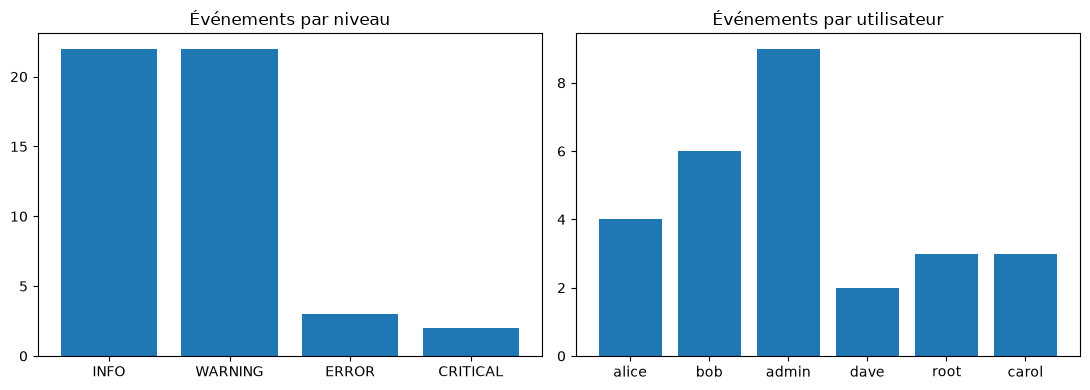

In [4]:
severities = count_by_severity(records)
users = count_by_user(records)
levels = list(SEVERITY_LEVELS)
level_counts = []
for level in levels:
    level_counts.append(severities[level])

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.bar(levels, level_counts)
left.set_title("Événements par niveau")
right.bar(list(users.keys()), list(users.values()))
right.set_title("Événements par utilisateur")
plt.tight_layout()
plt.show()

`admin` ressort nettement : c'est le compte visé par l'attaque par force
brute présente dans `auth.log`.

## 5. Analyse des adresses IP (Module 3, `set` et `frozenset`)

La blacklist est chargée dans un `frozenset` (non modifiable). Les IP
actives et les IP en erreur (niveau WARNING ou plus) sont des `set`.

In [5]:
blacklist = load_blacklist("data/samples/blacklist.txt")
active = active_ips(records)
errors = error_ips(records)
ips = compare_with_blacklist(blacklist, active, errors)

print(f"IP actives : {len(active)}, IP en erreur : {len(errors)}")
print()
print("blacklist & actives :", sorted(ips["blacklisted_and_active"]))
print("erreurs - blacklist :", sorted(ips["suspects_not_blacklisted"]))
print("blacklist | erreurs :", len(ips["new_blacklist"]), "IP")
print("blacklist ^ actives :", len(ips["in_only_one"]), "IP")

IP actives : 10, IP en erreur : 8

blacklist & actives : ['192.0.2.150', '198.51.100.77']
erreurs - blacklist : ['10.0.0.15', '10.0.0.22', '10.0.0.31', '127.0.0.1', '198.51.100.23', '203.0.113.45']
blacklist | erreurs : 10 IP
blacklist ^ actives : 10 IP


## 6. Détection de force brute (Module 3, boucles)

Les tentatives sont regroupées par IP (`for` + `continue`), puis une
boucle `while` cherche une série d'échecs consécutifs : `break` arrête la
recherche dès que le seuil est atteint, et la clause `else` de la boucle
signale qu'un cycle complet s'est terminé sans détection.

In [6]:
for threshold in (3, 5):
    print(f"Seuil {threshold} :")
    for attack in describe_attacks(records, threshold):
        print("   ", attack)

Seuil 3 :
    {'ip': '198.51.100.23', 'users': {'root'}, 'failures': 3, 'succeeded': False}
    {'ip': '203.0.113.45', 'users': {'admin'}, 'failures': 6, 'succeeded': True}
Seuil 5 :
    {'ip': '203.0.113.45', 'users': {'admin'}, 'failures': 6, 'succeeded': True}


## 7. Moteur de règles (Module 4, `*args` et `**kwargs`)

`apply_security_rules(records, *args, **kwargs)` reçoit un nombre
variable de règles (des fonctions) et une configuration libre.

In [7]:
alerts = apply_security_rules(
    records,
    rule_brute_force,
    rule_blacklisted_ips,
    rule_privilege_escalation,
    threshold=5,
    blacklist=blacklist,
)
for alert in alerts:
    print(f"[{alert['rule']}] {alert['ip']} : {alert['message']}")

[brute_force] 203.0.113.45 : 6 échecs sur admin (attaque réussie)
[blacklist] 192.0.2.150 : IP blacklistée présente dans les logs
[blacklist] 198.51.100.77 : IP blacklistée présente dans les logs
[privilege] 203.0.113.45 : admin a obtenu des droits élevés


## 8. Audit (Module 4, `globals()` et `locals()`)

`export_audit_report` décrit les variables d'une portée. Les noms
internes, modules et fonctions sont ignorés, les collections sont
résumées par leur taille et les secrets sont masqués.

In [8]:
def demo_audit():
    threshold = 5
    api_token = "jeton-secret"
    attacks = describe_attacks(records, threshold)
    return export_audit_report(os.devnull, globals(), locals())


report = demo_audit()
print(json.dumps(report["locals"], indent=2, ensure_ascii=False))
print("Variables globales auditées :", len(report["globals"]))

{
  "threshold": {
    "type": "int",
    "value": "5"
  },
  "api_token": {
    "type": "str",
    "value": "***"
  },
  "attacks": {
    "type": "list",
    "value": "1 éléments"
  }
}
Variables globales auditées : 22


## 9. Consommation mémoire

On mesure avec `tracemalloc` le pic de mémoire de quatre façons de
traiter un fichier de 100 000 lignes.

Taille du fichier : 8778 Ko
Générateur read_lines             22 Ko
Chaîne complète                   28 Ko
list(read_lines(...))          21652 Ko
readlines()                    13578 Ko


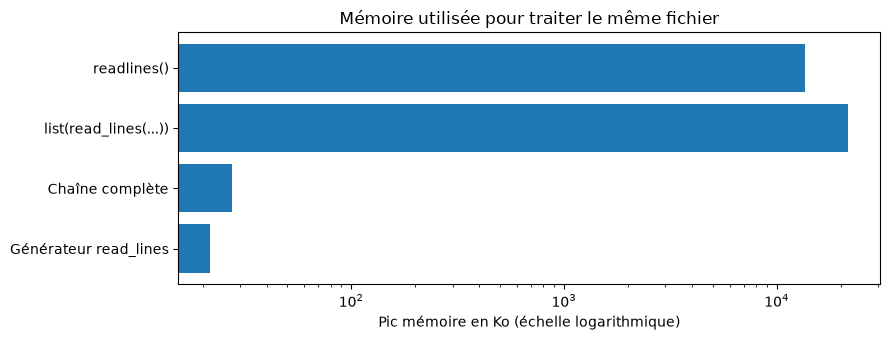

In [9]:
methods = [
    ("Générateur read_lines", read_with_generator),
    ("Chaîne complète", read_with_pipeline),
    ("list(read_lines(...))", read_with_list),
    ("readlines()", read_all_at_once),
]
names = []
peaks = []
with tempfile.TemporaryDirectory() as folder:
    path = os.path.join(folder, "demo.log")
    create_test_file(path, 100_000)
    size = os.path.getsize(path) / 1024
    for name, function in methods:
        names.append(name)
        peaks.append(measure_peak(function, path) / 1024)

print(f"Taille du fichier : {size:.0f} Ko")
for index in range(len(names)):
    print(f"{names[index]:<25} {peaks[index]:>10.0f} Ko")

plt.figure(figsize=(9, 3.5))
plt.barh(names, peaks)
plt.xscale("log")
plt.xlabel("Pic mémoire en Ko (échelle logarithmique)")
plt.title("Mémoire utilisée pour traiter le même fichier")
plt.tight_layout()
plt.show()

Le générateur et la chaîne complète restent à quelques dizaines de Ko,
quelle que soit la taille du fichier, alors que les méthodes qui
chargent tout en liste utilisent plusieurs dizaines de Mo.

## 10. Conclusion

**Résultats sur les fichiers d'exemple.** Le moteur détecte :

- l'attaque par force brute de `203.0.113.45` sur `admin` (6 échecs,
  attaque réussie), suivie d'une élévation de privilèges ;
- deux IP blacklistées présentes dans les logs, dont le scanner de ports
  `198.51.100.77` ;
- les IP suspectes absentes de la blacklist, à surveiller.

**Limites.**

- Les fichiers sont lus l'un après l'autre et non fusionnés par date.
- Les analyses (comptages, IP, règles) travaillent sur la liste des
  événements déjà filtrés, qui reste petite par rapport aux fichiers bruts.
- Les secrets de l'audit sont repérés par le nom de la variable
  uniquement.

**Améliorations possibles.** Fusion chronologique de plusieurs fichiers,
fenêtre de temps pour la force brute (X échecs en Y secondes), export du
rapport d'analyse en JSON.